```{contents}
:local:
:depth: 2
```

# 3.6 Surrogate-Based Optimization

:::{admonition} Draft status: first draft
:class: warning
First draft (2026-10-30), written from the course design notes. Not yet reviewed.
:::

```{admonition} Lectures
:class: tip
This topic accompanies these recorded lessons:

- Module 8 (second week), Lesson 8: *Exploration versus Exploitation and Adaptive Sampling*
- Module 8 (second week), Lesson 9: *Convergence in Model-Based Data-Driven Optimization*
- Module 8 (second week), Lesson 10: *Efficient Global Optimization Algorithm*
- Module 8 (second week), Lesson 11: *Mixed Integer Surrogate Optimization*
```

:::{admonition} Learning Objectives
:class: tip

By the end of this topic, you should be able to:

- Describe the adaptive loop and the exploration–exploitation trade-off.
- Implement efficient global optimization (EGO) with a Gaussian process and expected improvement.
- Explain how a GP's length scale decides whether EGO explores, and fix a run that does not.
- Handle optima on edges, unknown constraints and on/off decisions in a surrogate loop.
- Compare what branch-and-bound, DIRECT and EGO can certify.
:::

In Topic 3.5 we built each surrogate once from a fixed design, but in this topic the surrogate and the samples improve together as we fit, optimize, sample where the surrogate suggests, and then refit. This loop is the subject of the lectures for this topic, and it closes the data-driven optimization topics.

## The adaptive loop: exploration and exploitation

The lectures extend the steps of Topic 3.5 into a loop, where after optimizing the surrogate we evaluate the black box at the proposed point, add the result to the data, refit, and repeat until a stopping rule fires. Each new sample serves one of two purposes: **exploitation** samples where the surrogate predicts a good value in order to refine a promising region, while **exploration** samples where the surrogate has little data in order to improve the model and avoid missing a better region. A loop that only exploits converges quickly to whatever its first surrogate believes, while a loop that only explores ignores what it has learned. The lectures also frame the choice of surrogate as accuracy against complexity, since a simple model optimizes globally and cheaply but may be wrong, while a flexible model is accurate but non-convex to optimize. A global optimum of an inaccurate model is of little use, and a costly global solve of an accurate one must be weighed against simply collecting more samples in the same time.

The lectures add some practical rules for the first steps of the loop. We need to choose the inputs carefully, since wrong or strongly correlated inputs defeat every later step. Bounds are needed for the design, and if the solution lands near a bound we should widen it and repeat. The initial design must be large enough to fit the model, capture its nonlinearity and leave data for validation, and a common heuristic is about 10 points per input dimension, adjusted for the cost of a sample and the expected nonlinearity.

Deciding when to stop is harder (Lesson 9). The usual stopping rules are a sampling budget, a CPU budget, no improvement in $N$ consecutive iterations, or low validation error together with no improvement, and none of them guarantees even a local optimum. *Local* model-based methods, such as trust-region methods that fit a linear or quadratic model in a small region and then move or shrink it, inherit the convergence theory of direct search (Topic 3.2) but can get stuck. *Global* methods fit the whole domain and tend to reach the right region with fewer samples, although without any guarantee, so a common compromise is a short global surrogate search followed by a local, convergent method from its best point.

A **trust-region** method works as follows. At the iterate $x_k$ we fit a linear or quadratic model $m_k$ to samples within a radius $\Delta_k$ (by interpolation or regression on a well-poised set of points), and we minimize $m_k$ over the ball $\lVert s \rVert \le \Delta_k$ to get a trial step $s_k$. Then we evaluate the black box and compare the actual reduction with the predicted one, $\rho_k = [f(x_k) - f(x_k + s_k)]/[m_k(x_k) - m_k(x_k + s_k)]$. If $\rho_k$ is small (say below 0.1) the model is not trusted, so we reject the step and shrink $\Delta_k$; if it is moderate we accept the step and keep $\Delta_k$; and if $\rho_k$ is close to 1 and the step reached the boundary, we accept it and expand $\Delta_k$. The method stops when $\Delta_k$ becomes small. Because the model is checked against the black box at every step, and the sample geometry is controlled as in direct search, these methods converge to a stationary point (Conn, Scheinberg and Vicente, 2009, Chapters 10–11).

The simplest global loop is pure exploitation with a parametric model, which Topic 3.1 previewed on BB1 (where two A stacks share $D = 0.9$ with the decision $x_1$, the global optimum 1.5892 is at either edge, and a local trap of 1.6425 is at the equal split) by fitting a quadratic to a handful of samples and going to its minimum. We can repeat it on the same Latin hypercube samples, using 3, 5, 9 and 15 points that are taken from the shared helper `preview_samples`.

In [1]:
%matplotlib inline
import sys, warnings
sys.path.insert(0, '..')
warnings.filterwarnings('ignore')
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('../settings/plot_style.mplstyle')
from scipy.stats import norm, qmc
from sklearn.gaussian_process import GaussianProcessRegressor, GaussianProcessClassifier
from sklearn.gaussian_process.kernels import Matern, ConstantKernel, WhiteKernel
from _lib import electrolyzer as el
from _lib.part3a_tools import preview_samples, lipschitz_bb1, direct_certified

F1, F2, F3 = 1.58921, 2.08181, 2.32181            # optima of BB1, BB2, BB3 (Topics 2.6 and 3.3)
xs = np.linspace(0, 0.9, 901); f_true = np.array([el.bb1(x) for x in xs])
for n in (3, 5, 9, 15):
    X = preview_samples(n)                        # LHS on [0, 0.9], seed 1, as in Topic 3.1
    c = np.polyfit(X, [el.bb1(x) for x in X], 2)
    k = np.argmin(np.polyval(c, xs))
    print(f"n = {n:2d}: {'convex' if c[0] > 0 else 'concave'} quadratic, minimum at x1 = {xs[k]:.3f}, "
          f"true cost there {f_true[k]:.4f} ({el.to_mw(f_true[k] - F1)*1e3:.0f} kW above optimal)")

n =  3: convex quadratic, minimum at x1 = 0.247, true cost there 1.6719 (540 kW above optimal)
n =  5: convex quadratic, minimum at x1 = 0.578, true cost there 1.6547 (428 kW above optimal)
n =  9: convex quadratic, minimum at x1 = 0.000, true cost there 1.5892 (0 kW above optimal)
n = 15: convex quadratic, minimum at x1 = 0.118, true cost there 1.7054 (759 kW above optimal)


Every fit is convex, because the samples are dominated by the shallow bowl between the wells, so its minimum lies inside the domain or, if it falls outside, at the nearer edge. With 9 points the minimum fell just outside and was clipped to $x_1 = 0$, which happens to be optimal, but only because of where those samples fell, while with 15 points the fit is better on average and worse at the optimum. Since a quadratic cannot represent two wells at the edges, adding more data does not help.

:::{exercise}
:label: ex-t36-quadratic

Replace the quadratic by a quartic and repeat for the same four designs. Does the quartic's minimum land in a global well more often? Then repeat both fits for LHS seeds 0–19 at $n = 9$ and report how often each lands within $10^{-3}$ of the optimum.
:::

## Efficient global optimization

**Efficient global optimization** (EGO; Jones, Schonlau and Welch, 1998) replaces the quadratic with a Gaussian process, and it replaces "go to the minimum" with a criterion that weighs both goals. At a candidate $x$ the GP predicts a mean $\hat\mu(x)$ and a standard deviation $\hat\sigma(x)$, and if we assume that the black box value there is normally distributed with those moments, then the expected amount by which it improves on the best value so far, $f_{\min}$, is the **expected improvement** $\mathrm{EI}(x) = E\big[\max(f_{\min} - Y(x), 0)\big]$ with $Y(x) \sim N(\hat\mu(x), \hat\sigma(x)^2)$, which evaluates to

$$
\mathrm{EI}(x) = \big(f_{\min} - \hat\mu(x)\big)\,\Phi(z) + \hat\sigma(x)\,\phi(z), \qquad z = \frac{f_{\min} - \hat\mu(x)}{\hat\sigma(x)},
$$

where $\Phi$ and $\phi$ are the standard normal distribution and density, and the factor $\Phi(z)$ is the probability that the black box beats $f_{\min}$ at $x$. The first term rewards a low predicted mean (exploitation), while the second rewards uncertainty (exploration), so that EI is zero at sampled points and positive wherever the GP is unsure. EGO samples the black box at the maximizer of EI, refits, and repeats.

The lectures list the strengths of EGO, which are that the kriging model is flexible and accurate in promising regions, that local and global search are balanced, that the result depends less on the initial design because unsampled regions keep a high EI, and that stopping when EI is small is a more meaningful criterion than a budget. Its weaknesses are that EI is a new multimodal function to maximize at every step, that samples come one at a time (with no parallel evaluation), and that there is no proof of optimality. EGO is closely related to what machine learning calls Bayesian optimization, and implementations include TOMLAB in MATLAB and the `EGO` application of the Python Surrogate Modeling Toolbox (SMT).

Since the course notebook from Fani has no EGO implementation, we will write one from scratch in about 20 lines that maximizes EI over a dense candidate set (2,001 points in 1-D, 4,000 random points in 2-D), which is crude but transparent. The GP uses a Matérn 5/2 kernel with its length scale fitted by maximum likelihood, where the `cap` argument bounds that length scale and `edges` adds candidates on the faces of the box. We say that a run succeeds when it samples within $10^{-3}$ of the known optimum, and we give it 80 evaluations to do so. On BB1, the seed $s$ starts from the four points `preview_samples(4, seed=s)` that come from the design of Topic 3.1.

In [2]:
def gp(cap=None):
    bounds = (1e-5, 1e5) if cap is None else (1e-2, cap)
    k = ConstantKernel(1.0) * Matern(0.2, bounds, nu=2.5) + WhiteKernel(1e-6, (1e-10, 1e-2))
    return GaussianProcessRegressor(k, normalize_y=True, n_restarts_optimizer=2, random_state=0)

def ei(mu, sd, best):
    sd = np.maximum(sd, 1e-12); z = (best - mu) / sd
    return (best - mu) * norm.cdf(z) + sd * norm.pdf(z)

def candidates(d, lo, hi, rng, edges=False):
    if d == 1: return lo + np.linspace(0, 1, 2001)[:, None] * (hi - lo)     # includes both ends
    c = rng.random((4000, d))
    if edges:                                     # 800 extra points with one coordinate at 0 or 1
        e = rng.random((800, d)); e[np.arange(800), rng.integers(0, d, 800)] = rng.integers(0, 2, 800)
        c = np.vstack([c, e])
    return lo + c * (hi - lo)

def ego(f, lo, hi, fstar, seed, n0, cap=None, edges=False, budget=80, tol=1e-3):
    """EGO from an n0-point LHS; stops at the first sample within tol of fstar. Returns X, y."""
    rng, d = np.random.default_rng(seed), len(lo)
    X = lo + qmc.LatinHypercube(d=d, seed=seed).random(n0) * (hi - lo); y = np.array([f(x) for x in X])
    cand = candidates(d, lo, hi, rng, edges)
    while len(y) < budget and y.min() >= fstar + tol:
        m = gp(cap).fit(X, y); mu, sd = m.predict(cand, return_std=True)
        xn = cand[np.argmax(ei(mu, sd, y.min()))]
        X = np.vstack([X, xn]); y = np.append(y, f(xn))
    return X, y

def hits(runs, fstar, tol=1e-3):
    """Evaluation count at first success for each run (None = never within budget)."""
    return [int(np.argmax(y < fstar + tol)) + 1 if y.min() < fstar + tol else None for _, y in runs]

lo1, hi1 = np.array([0.0]), np.array([0.9])
runs_fit = [ego(el.bb1, lo1, hi1, F1, s, n0=4) for s in range(10)]
assert all(np.allclose(np.sort(X[:4, 0]), preview_samples(4, seed=s)) for s, (X, _) in enumerate(runs_fit))
print("BB1, fitted length scale, evaluations to success:", hits(runs_fit, F1))

BB1, fitted length scale, evaluations to success: [7, 77, None, 12, 7, None, None, 9, None, None]


With the length scale left to maximum likelihood, EGO finds the edge optimum quickly in 4 of 10 seeds (7 to 12 evaluations), while one more run stumbles onto it at evaluation 77 and the other 5 never find it in 80 evaluations. Since DIRECT needed 81 evaluations for its first hit on BB1 (Topic 3.3), the fast runs are very cheap, and the next section explains why the other runs fail.

:::{exercise}
:label: ex-t36-ei

Write the "pure exploitation" and "pure exploration" acquisitions, $-\hat\mu(x)$ and $\hat\sigma(x)$, and run each in place of EI on BB1 for seeds 0–9. Report the success counts and explain each result in terms of the two terms of EI.
:::

## Hyperparameters decide exploration

To see why half of the runs fail, we can look at what the GP believes. In a failing run (seed 2) the first samples straddle the equal split, and EI sends the next few samples near $x_1 = 0.45$. As samples pile up there, the maximum-likelihood length scale grows, and once it is longer than the domain the GP believes that the function is a single smooth bowl. This means that its band between samples collapses, EI sees nothing to gain anywhere else, and EGO keeps sampling the equal-split trap at 1.6425. Capping the length scale at 0.3 forces the GP to admit that it does not know the function between samples that are farther apart than that.

fitted length scale       : length scale 1.46, max band 0.0114, next sample at x1 = 0.450
length scale capped at 0.3: length scale 0.30, max band 0.0191, next sample at x1 = 0.000


findfont: Failed to find font weight ultralight for Helvetica, now using 300.


findfont: Failed to find font weight ultralight for Helvetica, now using 300.


findfont: Failed to find font weight ultralight for Helvetica, now using 300.


BB1, capped length scale, evaluations to success: [7, 11, 8, 12, 8, 10, 15, 9, 51, 10]  median 10


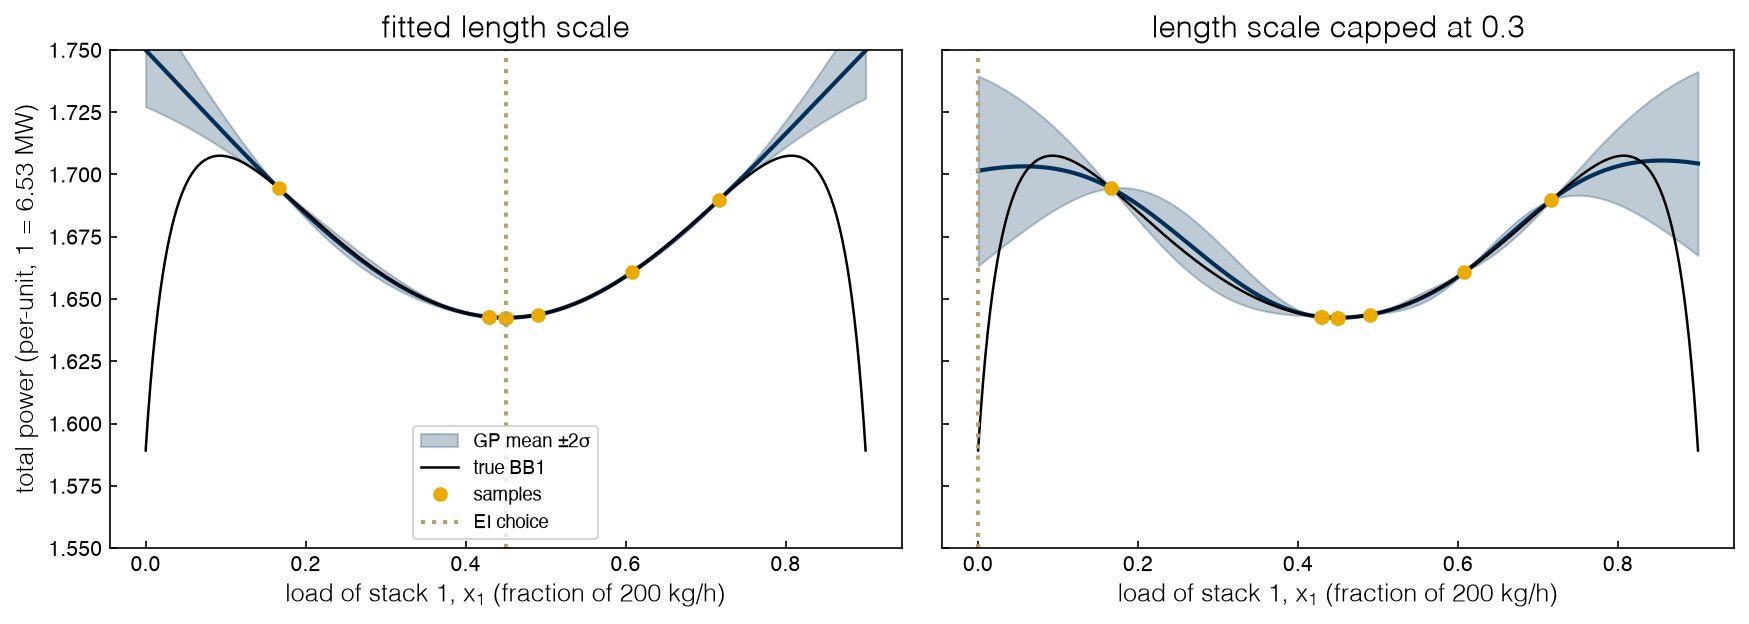

In [3]:
Xf, yf = runs_fit[2][0][:8], runs_fit[2][1][:8]           # seed 2, after 8 evaluations
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, cap, title in ((axs[0], None, 'fitted length scale'), (axs[1], 0.3, 'length scale capped at 0.3')):
    m = gp(cap).fit(Xf, yf); mu, sd = m.predict(xs[:, None], return_std=True)
    nxt = xs[np.argmax(ei(mu, sd, yf.min()))]
    print(f"{title:26s}: length scale {m.kernel_.k1.k2.length_scale:.2f}, max band {sd.max():.4f}, "
          f"next sample at x1 = {nxt:.3f}")
    ax.fill_between(xs, mu - 2 * sd, mu + 2 * sd, color='C0', alpha=0.25, label='GP mean $\\pm 2\\sigma$')
    ax.plot(xs, mu, 'C0'); ax.plot(xs, f_true, 'k', lw=1.2, label='true BB1')
    ax.plot(Xf[:, 0], yf, 'o', color='C1', label='samples'); ax.axvline(nxt, color='C3', ls=':', label='EI choice')
    ax.set_title(title); ax.set_xlabel('load of stack 1, $x_1$ (fraction of 200 kg/h)')
axs[0].set_ylabel('total power (per-unit, 1 = 6.53 MW)'); axs[0].legend(fontsize=9)
ax.set_ylim(1.55, 1.75)

runs_cap = [ego(el.bb1, lo1, hi1, F1, s, n0=4, cap=0.3) for s in range(10)]
h = hits(runs_cap, F1)
print("BB1, capped length scale, evaluations to success:", h, " median", int(np.median(h)))

On the same eight samples, the length scale of the fitted GP (1.46) exceeds the 0.9-wide domain and its band is narrow everywhere (at most 0.011 per-unit), so EI chooses the trap at $x_1 = 0.45$ again. The capped GP keeps wider bands toward the edges (up to 0.019), which means that EI goes to the edge $x_1 = 0$. Over all 10 seeds the capped EGO succeeds every time, with a median of 10 evaluations (one seed needs 51).

The main lesson of this topic is that **hyperparameters decide exploration versus exploitation**. EI is often described as balancing the two automatically, but it balances them only as well as $\hat\sigma(x)$ is honest, and since $\hat\sigma$ is set by the length scale, a long length scale says "I already know the shape" while a capped one says "keep looking". Maximum likelihood that is fitted to a few clustered samples is a poor judge of shape, which nothing in the loop corrects, so bounding the hyperparameters from what we know about the problem (here, that the domain is narrow and the wells are sharp) is part of setting up EGO.

:::{exercise}
:label: ex-t36-lengthscale

Repeat the capped runs with caps of 0.1, 0.3, 0.6 and 0.9. Plot success count and median evaluations against the cap. Is there a cap that is too small? Explain what EGO does then.
:::

## Optima on the edge

In BB2 the stacks A, B and C share $D = 1.2$, with inputs $(x_A, x_B)$ in the unit box, C taking the rest, and a penalty of 10 if the load of C leaves $[0, 1]$, which means that the optimum 2.0818 lies on the edge $x_B = 0$ where stack B is off. Topic 3.3 met this as a measure-zero optimum that random sampling never hits, and it returns here because the EI maximizer that we wrote searches 4,000 random candidates, none of which has $x_B$ exactly 0. We will compare EGO with and without 800 extra candidates on the faces of the box, starting from 10 LHS points in both cases.

In [4]:
lo2, hi2 = np.zeros(2), np.ones(2)
for edges in (False, True):
    h = hits([ego(el.bb2, lo2, hi2, F2, s, n0=10, edges=edges) for s in range(10)], F2)
    ok = [v for v in h if v]
    print(f"BB2, edge candidates {str(edges):5s}: success {len(ok)}/10, "
          f"median evaluations {np.median(ok) if ok else '-'}")

BB2, edge candidates False: success 0/10, median evaluations -


BB2, edge candidates True : success 10/10, median evaluations 31.5


Without edge candidates EGO never succeeds, while with them it succeeds in all 10 seeds, taking a median of 31.5 evaluations compared to the 835 that DIRECT needed for its first hit in Topic 3.3. The fix changes the candidate set and leaves the model alone, which tells us that if an optimum may turn a stack off, the optimizer of the acquisition function must be able to propose "off".

:::{exercise}
:label: ex-t36-edges

Run BB2 with the capped length scale (0.3), with and without edge candidates. Does capping help here as it did on BB1? Suggest why BB2 behaves differently.
:::

## Constraints by surrogate

BB3 is the full MINLP as a black box, where a load below the minimum $x_{\min} = 0.1$ means that the stack is off, a stack that is on pays a fixed charge, and any split that C cannot absorb returns the penalty 10. Its optimum, A + C at loads (0.703, 0.497) with B off, costs 2.3218 (15.17 MW). Topic 3.4 compared two ways to handle such constraints with direct methods, and here we look at the surrogate versions.

1. **Penalized GP.** One GP on the penalized objective, exactly as above.
2. **Feasibility classifier.** A GP regressor on the feasible samples only, times a GP classifier's probability of feasibility $P_f(x)$, with the acquisition $\mathrm{EI}(x)\,P_f(x)$.
3. **Gated classifier.** The same two models, but EI is computed only on candidates with $P_f(x) \ge 0.5$.
4. **Per-constraint surrogate.** If the black box reports the constraint's value and not only pass or fail, model the constraint itself. Here the plant meters stack C's load $x_C$, which must satisfy $x_{\min} \le x_C \le 1$ when C is on. A second GP models $x_C(x)$ from *all* samples, and its prediction gives $P_f(x) = \Phi\big((1 - \hat\mu_g)/\hat\sigma_g\big)\,\Phi\big((\hat\mu_g - x_{\min})/\hat\sigma_g\big)$, treating the two bounds as independent; the acquisition is $\mathrm{EI}(x)\,P_f(x)$ with the objective GP fitted to feasible points, as before. With $J$ black-box constraints there is one GP per constraint and the probabilities multiply.

In [5]:
def constrained_ego(f, X, y, cand, mode, fstar, budget=80, tol=1e-3, pen=el.PENALTY):
    """EGO with a feasible-only GP and a GP feasibility classifier. mode: 'product' or 'gate'."""
    while len(y) < budget and y.min() >= fstar + tol:
        feas = y < pen
        mu, sd = gp().fit(X[feas], y[feas]).predict(cand, return_std=True)
        pf = GaussianProcessClassifier(1.0 * Matern(0.2, nu=2.5), random_state=0).fit(X, feas).predict_proba(cand)[:, 1]
        a = ei(mu, sd, y[feas].min())
        a = a * pf if mode == 'product' else np.where(pf >= 0.5, a, -1.0)
        xn = cand[np.argmax(a)]; X = np.vstack([X, xn]); y = np.append(y, f(xn))
    return X, y

print("penalized GP:", hits([ego(el.bb3, lo2, hi2, F3, s, n0=10) for s in range(10)], F3))
for mode in ('product', 'gate'):
    runs = []
    for s in range(10):
        X0 = qmc.LatinHypercube(d=2, seed=s).random(10)
        runs.append(constrained_ego(el.bb3, X0, np.array([el.bb3(x) for x in X0]),
                                    np.random.default_rng(s).random((4000, 2)), mode, F3))
    h = hits(runs, F3); share = [np.mean(y < el.PENALTY) for _, y in runs]
    fail = [y[y < el.PENALTY].min() for (_, y), v in zip(runs, h) if v is None]
    print(f"classifier, {mode:7s}: {h}; feasible share of samples {np.mean(share):.0%}; "
          f"best feasible value in failed runs {np.round(fail, 4)}")

def x_c(x):                                       # stack C's metered load, a reported constraint value
    xa, xb = (0.0 if v < el.X_MIN else float(v) for v in x[:2]); return 1.2 - xa - xb
runs = []
for s in range(10):
    X = qmc.LatinHypercube(d=2, seed=s).random(10); y = np.array([el.bb3(x) for x in X])
    g = np.array([x_c(x) for x in X]); cand = np.random.default_rng(s).random((4000, 2))
    while len(y) < 80 and y.min() >= F3 + 1e-3:
        feas = y < el.PENALTY
        mu, sd = gp().fit(X[feas], y[feas]).predict(cand, return_std=True)
        mg, sg = gp().fit(X, g).predict(cand, return_std=True); sg = np.maximum(sg, 1e-9)
        pf = norm.cdf((1 - mg) / sg) * norm.cdf((mg - el.X_MIN) / sg)
        xn = cand[np.argmax(ei(mu, sd, y[feas].min()) * pf)]
        X = np.vstack([X, xn]); y = np.append(y, el.bb3(xn)); g = np.append(g, x_c(xn))
    runs.append((X, y))
h = hits(runs, F3)
print(f"per-constraint GP: {h}; feasible share of samples {np.mean([np.mean(y < el.PENALTY) for _, y in runs]):.0%}; "
      f"best value in failed runs {[round(float(y.min()), 4) for (_, y), v in zip(runs, h) if v is None]}")

penalized GP: [34, 38, 20, 22, 57, 42, 11, 17, 12, 17]


classifier, product: [None, None, 23, 40, None, 13, 11, 16, None, None]; feasible share of samples 44%; best feasible value in failed runs [2.3304 2.3303 2.3301 2.3301 2.3301]


classifier, gate   : [25, 61, 25, 41, 23, 13, 15, 16, 42, 19]; feasible share of samples 75%; best feasible value in failed runs []


per-constraint GP: [21, None, 20, 34, 20, 13, 15, 16, 39, None]; feasible share of samples 79%; best value in failed runs [2.3261, 2.3238]


The penalized GP succeeds in all 10 seeds, while the classifier with the product acquisition succeeds in only 5. It is tempting to blame the boundary, as if the optimum sat where the classifier is unsure, but the optimum is well inside the feasible region (B off is legal, and A + C leaves margin on every constraint), and the printed output shows what happens instead. Only 44% of the samples in the product runs are feasible, and every run that fails stalls at 2.3301, the runner-up configuration B + C, 0.4% worse (the near-tie of Topic 2.6). Since a GP that is trained on feasible points only has no data in the infeasible region, it extrapolates there with an optimistic mean and a wide band, so EI is large exactly where the black box returns the penalty, and multiplying by a moderate $P_f$ does not suppress it enough. As a result the runs spend their budget on infeasible points and on the region that they already know, so that they rarely sample the narrow strip $x_B < 0.1$ where B is off.

Gating removes the optimistic extrapolation, because the regressor is never asked about points that the classifier considers more likely infeasible than not, and the gated runs succeed in all 10 seeds, with 75% of samples feasible. More generally, a surrogate that is trained on part of the space should not be trusted outside that part, and the acquisition should know where that part ends.

The per-constraint surrogate succeeds in 8 of 10 seeds with 79% of its samples feasible, which is more than either classifier variant (44% and 75%). Because the constraint GP is fitted to every sample, including the infeasible ones, it knows where the infeasible region is without a gate. Its two failures end at 2.3238 and 2.3261, which are already in the A + C configuration (below the B + C value 2.3301) but are not within the $10^{-3}$ tolerance after 80 evaluations. When a black box reports constraint values it pays to use them, since a value says how far from feasible a point is, while a pass/fail label only says which side it is on.

:::{exercise}
:label: ex-t36-gate

Vary the gate threshold over 0.2, 0.5 and 0.8 and report the success count and median evaluations. Then replace the gate by the product $\mathrm{EI}\,P_f^3$. Which acquisition would you trust on a new black box, and why?
:::

## Mixed-integer surrogates

Lesson 11 turns to discrete decisions, which Topic 3.3 flagged as the wrong job for derivative-free methods, because two problems arise when a surrogate has to handle them: a simulator may fail at non-integer values of an integer input, so that no sample is obtained at all, and regression models treat inputs as ordinal, even though a binary "unit on" is not an intensity.

The lectures review three approaches, which are brute force that decouples the binaries and solves one NLP per configuration (expensive when configurations are many); relaxed surrogates that treat binaries as continuous on $[0, 1]$ (Müller, 2016; less accurate); and mixed-integer surrogates that are built directly (Mistry et al., 2018; harder to sample and optimize). They also give three sampling strategies for mixed spaces, which are a **balanced** design (a separate LHS for each discrete level), a **randomized** design (one LHS, with points assigned to levels at random), and an LHS with the binary coordinates **rounded**. With $m$ discrete levels and $d$ variables in total, the number of points that each level gets is $n_{\mathrm{LHS}} = \max\big(5, \lceil (10d + 1)/m \rceil\big)$, so that every level is represented evenly in the design.

The fix for ordinality in the lectures is **one-hot encoding**, where a discrete choice with $K$ options becomes $K$ indicator inputs, exactly one of which is 1, so that no option is "between" two others. In a neural network there is a second reason, since a binary input of 0 multiplies its weights by zero, which means that the network cannot learn the effect of the "off" level, while with one indicator per level each level carries its own signal. The adaptive surrogate-MINLP algorithm then has four steps, which are a mixed-integer initial design; one-hot encoding and fitting; optimizing the surrogate MINLP with adaptive sampling; and finally fixing the discrete choice and solving the remaining NLP to refine the continuous variables.

For the electrolyzer, the discrete decision is which stacks are on, which gives 7 nonempty configurations of A, B, C. We one-hot encode the configuration as 7 inputs and add two continuous dials in $[0, 1]$, and in a configuration every on stack but the last (in the order A, B, C) runs at $x_{\min} + u\,(1 - x_{\min})$, with $u$ its dial, and the last on stack takes the rest of $D = 1.2$, while an infeasible remainder returns the penalty. We draw a balanced design of 3 LHS points per configuration (21 in all) and then run an adaptive surrogate-MINLP loop, and since there are only 7 configurations, each iteration simply scores 600 random dial settings in every configuration with EI and samples the best. We will try a penalized GP and the gated classifier from the previous section.

In [6]:
import itertools
CONFIGS = [c for r in (1, 2, 3) for c in itertools.combinations('ABC', r)]

def bb_mi(k, u, D=1.2):
    """Configuration k (index into CONFIGS) with dials u: the last on stack takes the remainder."""
    cfg, x = CONFIGS[k], dict(A=0.0, B=0.0, C=0.0)
    for s, ui in zip(cfg[:-1], u): x[s] = el.X_MIN + ui * (1 - el.X_MIN)
    x[cfg[-1]] = D - sum(x.values())
    return el.fleet_cost([x[s] for s in 'ABC']) if el.X_MIN <= x[cfg[-1]] <= 1 else el.PENALTY

def mi_loop(seed, mode, budget=80, tol=1e-3):
    rng = np.random.default_rng(seed)
    enc = lambda k, U: np.hstack([np.tile(np.eye(7)[k], (len(U), 1)), U])       # one-hot + dials
    X = np.vstack([enc(k, qmc.LatinHypercube(d=2, seed=7 * seed + k).random(3)) for k in range(7)])
    y = np.array([bb_mi(int(np.argmax(r[:7])), r[7:]) for r in X])
    while len(y) < budget and y.min() >= F3 + tol:
        cand = np.vstack([enc(k, rng.random((600, 2))) for k in range(7)])
        if mode == 'penalized':
            mu, sd = gp().fit(X, y).predict(cand, return_std=True); a = ei(mu, sd, y.min())
        else:
            feas = y < el.PENALTY
            mu, sd = gp().fit(X[feas], y[feas]).predict(cand, return_std=True)
            pf = GaussianProcessClassifier(1.0 * Matern(0.5, nu=2.5), random_state=0).fit(X, feas).predict_proba(cand)[:, 1]
            a = np.where(pf >= 0.5, ei(mu, sd, y[feas].min()), -1.0)
        xn = cand[np.argmax(a)]; X = np.vstack([X, xn]); y = np.append(y, bb_mi(int(np.argmax(xn[:7])), xn[7:]))
    return X, y

for mode in ('penalized', 'gated'):
    runs = [mi_loop(s, mode) for s in range(10)]
    h = hits(runs, F3); ok = [v for v in h if v]
    print(f"{mode:9s}: {h}; success {len(ok)}/10, median {np.median(ok):.0f} evaluations")
X, y = runs[0]; best = X[np.argmin(y)]; k = int(np.argmax(best[:7]))
print(f"seed 0 finds {' + '.join(CONFIGS[k])} at dial {best[7]:.3f} (x_A = {el.X_MIN + best[7] * 0.9:.3f}, "
      f"{el.to_kg_h(el.X_MIN + best[7] * 0.9):.0f} kg/h), cost {y.min():.5f} = {el.to_mw(y.min()):.2f} MW")
from scipy.optimize import minimize_scalar                     # step 4: fix the configuration, refine the NLP
r = minimize_scalar(lambda u: bb_mi(k, [u]), bounds=(0, 1), method='bounded', options={'xatol': 1e-7})
print(f"refined: x_A = {el.X_MIN + r.x * 0.9:.3f} ({el.to_kg_h(el.X_MIN + r.x * 0.9):.0f} kg/h), "
      f"cost {r.fun:.5f}, {r.nfev} more evaluations")

penalized: [25, 62, 25, 37, 25, 37, 13, 13, 36, 26]; success 10/10, median 26 evaluations


gated    : [29, 35, 35, 29, 22, 32, 13, 13, 33, 27]; success 10/10, median 29 evaluations
seed 0 finds A + C at dial 0.660 (x_A = 0.694, 139 kg/h), cost 2.32190 = 15.17 MW
refined: x_A = 0.703 (141 kg/h), cost 2.32181, 9 more evaluations


Both loops find A + C at $D = 1.2$ in all 10 seeds, with the penalized GP taking a median of 26 evaluations and the gated one taking 29, from 21 initial points. In seed 0 the loop settles on A at 139 kg/h with C carrying the rest, which is within $10^{-3}$ of the optimum, and fixing A + C and refining the single dial (step 4) recovers the Topic 2.6 optimum, A at 141 kg/h and 2.32181, in 9 more evaluations. Unlike on BB3, the penalized GP does not fail here, and since we have not isolated why, on a new problem we would run both.

The lectures close with a harder case from Fani's research, a process-synthesis superstructure in the style of the Duran and Grossmann (1986) benchmark with 9 continuous and 8 binary variables and 23 constraints (21 inequalities and 2 equalities). The material balances and the logical unit-selection constraints are known equations, while the input–output relations of the units are treated as black boxes, and 8 of the constraints are gray-box. The adaptive surrogate-MINLP algorithm is compared with alternatives by its solution quality, feasibility and CPU time, which are summarized as a performance profile. The case shows the structure that we should aim for, where known constraints stay as equations and only unknown relations become surrogates.

:::{exercise}
:label: ex-t36-onehot

Replace the one-hot encoding by three binary inputs $(y_A, y_B, y_C)$, one per stack, and rerun the gated loop. Which configurations does the GP now treat as "close" to each other, and does the success count change? Then try the randomized design (21 points assigned to configurations at random) in place of the balanced one.
:::

## Find versus prove

The data-driven optimization topics opened (Topic 3.1) with the question of what a black-box method can promise, so we will close it by solving BB1 in three different ways and asking what each of them certifies.

1. **Spatial branch-and-bound on the equations** (Topic 2.6). Each node relaxes the concave part of the S-curve with its secant, which gives a valid lower bound; branching tightens the secants until the bounds meet.
2. **DIRECT with a Lipschitz constant** (Topic 3.3). On the black box, given $L \ge \max |f'|$, each interval's center value minus $L$ times its half-width is a valid lower bound.
3. **EGO with the capped length scale**, from above. It has an incumbent and no bound.

Branch-and-bound lives in `_lib/part3b_tools.py`, and DIRECT with $L$ is the routine of Topic 3.3 in `_lib/part3a_tools.py`. In order to put all three on one axis we count **model queries**, which are one black-box evaluation for DIRECT and EGO and one relaxation solve for branch-and-bound. We follow the node convention of Topic 2.6, where the spatial tree on BB1 has 12 nodes processed and 19 nodes created and each node that is created costs one relaxation solve, so that the branch-and-bound curve is plotted against relaxation solves (that is, against nodes created). Since a relaxation solve queries the equations instead of the black box, it is not the same currency, and the figure says so. Where a method has a bound we plot the gap (incumbent minus bound), while for EGO we plot the incumbent minus the true optimum, which is something that only we know.

branch-and-bound: 12 nodes processed, 19 created (one relaxation solve each), 9 spatial branches, optimum 1.58921 = 10.386 MW, gap 0e+00
DIRECT with L = 5.13: gap <= 1e-2 after 73 evaluations, <= 1e-3 after 83
EGO (capped): within 1e-3 of the optimum after [7, 8, 8, 9, 10, 10, 11, 12, 15, 51] evaluations, no bound


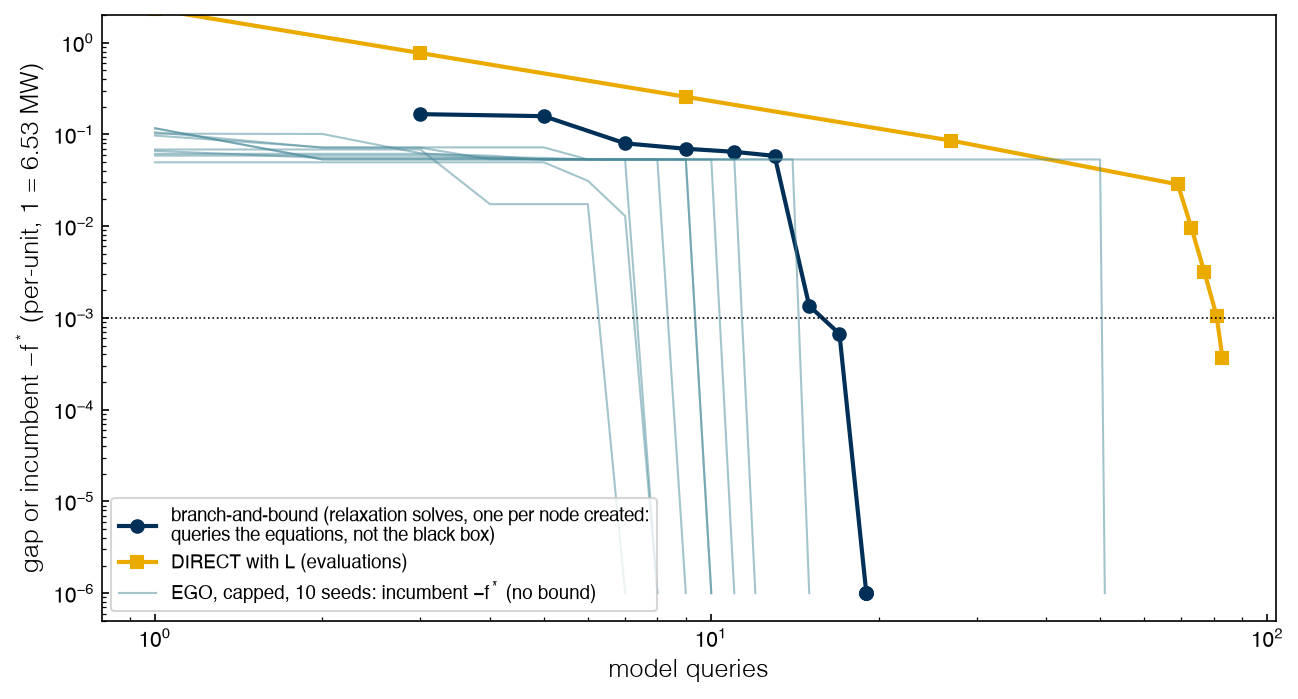

In [7]:
from _lib import part3b_tools as p3

bb = p3.spatial_bb_bb1()
L = lipschitz_bb1()
n_direct, hist_direct = direct_certified(local=False, tol=1e-3)          # shared with Topic 3.3
fstar = bb['ub']
print(f"branch-and-bound: {bb['nodes']} nodes processed, {bb['solves']} created (one relaxation solve each), "
      f"{bb['spatial']} spatial branches, optimum {bb['ub']:.5f} = {el.to_mw(bb['ub']):.3f} MW, gap {bb['ub'] - bb['lb']:.0e}")
print(f"DIRECT with L = {L:.2f}: gap <= 1e-2 after "
      f"{next(n for n, b, l in hist_direct if b - l <= 1e-2)} evaluations, <= 1e-3 after {n_direct}")
print(f"EGO (capped): within 1e-3 of the optimum after {sorted(hits(runs_cap, F1))} evaluations, no bound")

fig, ax = plt.subplots(figsize=(9, 5))
hb = np.array(bb['history']); ax.semilogy(hb[:, 0], np.maximum(hb[:, 1] - hb[:, 2], 1e-6), 'o-',
            label='branch-and-bound (relaxation solves, one per node created:\nqueries the equations, not the black box)')
hd = np.array(hist_direct); ax.semilogy(hd[:, 0], hd[:, 1] - hd[:, 2], 's-', label='DIRECT with $L$ (evaluations)')
for i, (_, y) in enumerate(runs_cap):
    ax.semilogy(np.arange(1, len(y) + 1), np.maximum(np.minimum.accumulate(y) - fstar, 1e-6), color='C2',
                alpha=0.5, lw=1, label='EGO, capped, 10 seeds: incumbent $-f^*$ (no bound)' if i == 0 else None)
ax.set_xscale('log'); ax.axhline(1e-3, color='k', lw=0.8, ls=':')
ax.set_xlabel('model queries'); ax.set_ylabel('gap or incumbent $-f^*$ (per-unit, 1 = 6.53 MW)')
ax.set_ylim(5e-7, 2); ax.legend(fontsize=9, loc='lower left');

Branch-and-bound proves the optimum (1.58921, 10.386 MW) with 12 nodes processed and 19 created (one relaxation solve each), although it can do this only because it is able to read the equations and build secants. DIRECT proves it on the black box with only a valid $L = 5.13$, closing the gap to $10^{-2}$ after 73 evaluations and to $10^{-3}$ after 83. Capped EGO *finds* the optimum in a median of 10 evaluations, which is roughly 8 times fewer than DIRECT, but it cannot say that it has, because expected improvement is a heuristic expectation rather than a bound, and a small EI means only that the GP sees nothing promising, as was also the case for the uncapped EGO runs that sat in the trap with a small EI.

In thermodynamic terms the gap is power, so a gap of $10^{-3}$ per-unit is 6.5 kW out of a plant drawing about 10.4 MW, which is below what a power meter on the fleet would resolve.

In economic terms, a certificate is worth paying for when a wrong answer is expensive and the evaluations are cheap enough, while EGO is worth using when every evaluation costs a plant run and a good answer now beats a proven answer later. The rule from Topic 2.6 still holds: *the moment you trust a bound from a non-convex problem, you are doing global optimization*, and since EGO never offers a bound, it never asks for that trust.

:::{exercise}
:label: ex-t36-find-prove

Give DIRECT the Lipschitz constant $L/2$ (too small, so invalid) and rerun it. Does it still report a closed gap? Is the reported optimum still correct? Explain what this says about trusting a certificate whose assumptions you cannot check on a black box.
:::

## Summary

- Surrogate-based optimization alternates fitting, optimizing and sampling, each sample exploiting or exploring; stopping rules are heuristics, not optimality conditions. Trust-region methods trade globality for local convergence.
- EGO maximizes expected improvement on a GP. With a fitted length scale it solves BB1 quickly in 4 of 10 seeds; capped at 0.3, in 10 of 10 (median 10 evaluations). Hyperparameters decide exploration.
- Optima that switch a stack off lie on edges: EGO on BB2 goes from 0 to 10 successes with edge candidates.
- On BB3: penalized GP 10/10; feasible-only GP times classifier 5/10, from optimistic extrapolation into the infeasible region; gating at $P_f \ge 0.5$ 10/10; a per-constraint GP 8/10.
- One-hot encoding, a balanced design and an adaptive loop find A + C at $D = 1.2$ in every seed.
- Branch-and-bound proves with equations, DIRECT proves with a Lipschitz constant, EGO finds without proof.

## Additional Reading

- D. R. Jones, M. Schonlau and W. J. Welch, "Efficient global optimization of expensive black-box functions," *Journal of Global Optimization* 13, 455–492 (1998).
- A. I. J. Forrester, A. Sóbester and A. J. Keane, *Engineering Design via Surrogate Modelling: A Practical Guide*, Wiley (2008). Chapters 3–5 on infill criteria, constraints and expected improvement.
- A. R. Conn, K. Scheinberg and L. N. Vicente, *Introduction to Derivative-Free Optimization*, SIAM (2009). Chapters 10–11 on model-based trust-region methods and their convergence.
- M. A. Duran and I. E. Grossmann, "An outer-approximation algorithm for a class of mixed-integer nonlinear programs," *Mathematical Programming* 36, 307–339 (1986). The source of the process-synthesis benchmark.
- A. Bhosekar and M. Ierapetritou, "Advances in surrogate based modeling, feasibility analysis, and optimization: A review," *Computers & Chemical Engineering* 108, 250–267 (2018).